In [1]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Data load
d = np.load("../data/processed/data.npz")
X_train, X_val = d["X_train"], d["X_val"]
y_train, y_val = d["y_train"], d["y_val"]

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    # log se wapas asli price
    y_true = np.expm1(y_val)
    y_pred = np.expm1(pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name}: RMSE={rmse:,.0f}  MAE={mae:,.0f}  R2={r2:.3f}")

evaluate("Linear Regression", LinearRegression())
evaluate("Random Forest", RandomForestRegressor(n_estimators=200, random_state=42))

Linear Regression: RMSE=26,743  MAE=20,504  R2=0.868
Random Forest: RMSE=26,956  MAE=19,561  R2=0.866


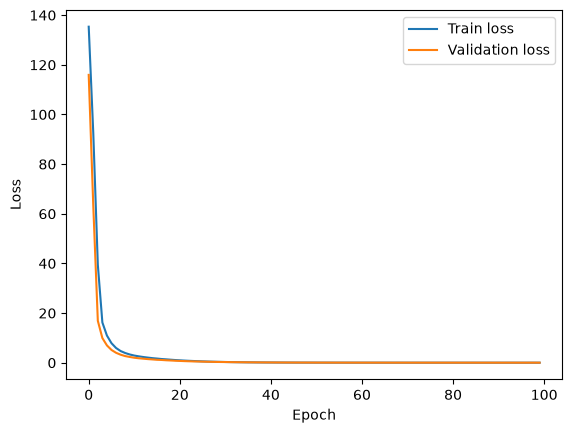

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
MAE: 22565
R2: 0.796


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, r2_score

d = np.load("../data/processed/data.npz")
X_train, X_val = d["X_train"], d["X_val"]
y_train, y_val = d["y_train"], d["y_val"]

model = keras.Sequential([
    layers.Input(shape=(6,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
model.compile(optimizer="adam", loss="mse")

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=100, batch_size=32, verbose=0)

# Learning curve
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

# Score
pred = np.expm1(model.predict(X_val).flatten())
true = np.expm1(y_val)
print("MAE:", round(mean_absolute_error(true, pred)))
print("R2:", round(r2_score(true, pred), 3))